In [5]:
import numpy as np
import plotly.graph_objects as go

# --- Parameters ---
R = 6371  # Earth's radius in km
d_target = 60  # desired average spacing in km
num_additional_circles = 8  # 5 more + previous 3 = 8
circle_radius_km = 1000  # 2000 km diameter

# --- Fibonacci points ---
A = 4 * np.pi * R**2
N = int(A / d_target**2)
indices = np.arange(0, N, dtype=float) + 0.5
phi = np.arccos(1 - 2*indices/N)
theta = np.pi * (1 + 5**0.5) * indices
x = R * np.sin(phi) * np.cos(theta)
y = R * np.sin(phi) * np.sin(theta)
z = R * np.cos(phi)
points = np.vstack([x, y, z]).T

# --- Generate circle centers (1 front-facing + 8 random) ---
circle_centers = [np.array([0.0, 0.0, 1.0])]
for _ in range(num_additional_circles):
    phi_rand = np.arccos(1 - 2*np.random.rand())
    theta_rand = 2 * np.pi * np.random.rand()
    x_c = np.sin(phi_rand) * np.cos(theta_rand)
    y_c = np.sin(phi_rand) * np.sin(theta_rand)
    z_c = np.cos(phi_rand)
    circle_centers.append(np.array([x_c, y_c, z_c]))

# --- Color points inside any circle red ---
alpha = circle_radius_km / R  # angular radius in radians
point_colors = np.full(N, 'blue', dtype=object)

for center in circle_centers:
    dot = points @ center
    dot /= np.linalg.norm(points, axis=1)
    dot /= np.linalg.norm(center)
    angles = np.arccos(np.clip(dot, -1, 1))
    inside_mask = angles <= alpha
    point_colors[inside_mask] = 'red'

# --- Earth surface mesh (opaque) ---
phi_surf, theta_surf = np.mgrid[0:np.pi:100j, 0:2*np.pi:200j]
x_surf = R * np.sin(phi_surf) * np.cos(theta_surf)
y_surf = R * np.sin(phi_surf) * np.sin(theta_surf)
z_surf = R * np.cos(phi_surf)
surface = go.Surface(x=x_surf, y=y_surf, z=z_surf,
                     colorscale='Earth', cmin=-R, cmax=R,
                     showscale=False, opacity=1.0)

# --- Points trace ---
offset = 0.01 * R
points_trace = go.Scatter3d(
    x=x*(1+offset/R), y=y*(1+offset/R), z=z*(1+offset/R),
    mode='markers',
    marker=dict(size=2, color=point_colors.tolist(), opacity=0.8),
    name='Fibonacci Points'
)

# --- Draw circles ---
circle_traces = []
theta_circle = np.linspace(0, 2*np.pi, 200)
circle_offset = 0.02 * R
for center in circle_centers:
    u = np.array([1.0, 0.0, 0.0])
    if np.allclose(center, u):
        u = np.array([0, 1, 0])
    v = np.cross(center, u)
    v /= np.linalg.norm(v)
    u = np.cross(v, center)
    u /= np.linalg.norm(u)

    circle_points = []
    for t in theta_circle:
        vec = alpha * (np.cos(t)*u + np.sin(t)*v)
        vec_norm = np.linalg.norm(vec)
        p_unit = np.cos(vec_norm)*center + np.sin(vec_norm)*(vec/vec_norm)
        p = R * p_unit * (1 + circle_offset / R)
        circle_points.append(p)
    circle_points = np.array(circle_points)
    
    trace = go.Scatter3d(
        x=circle_points[:,0], y=circle_points[:,1], z=circle_points[:,2],
        mode='lines', line=dict(color='red', width=5),
        name='2000 km Circle'
    )
    circle_traces.append(trace)

# --- Poles ---
pole_offset = 0.02 * R
north_pole = go.Scatter3d(
    x=[0], y=[0], z=[R + pole_offset],
    mode='markers+text', marker=dict(size=5, color='orange'),
    text=['N'], textposition='top center'
)
south_pole = go.Scatter3d(
    x=[0], y=[0], z=[-R - pole_offset],
    mode='markers+text', marker=dict(size=5, color='orange'),
    text=['S'], textposition='bottom center'
)

# --- Lat/Lon lines ---
lat_lines = []
for lat_deg in np.arange(-90, 91, 15):
    lat = np.radians(lat_deg)
    lon = np.linspace(0, 2*np.pi, 200)
    x_lat = R*np.cos(lat)*np.cos(lon)
    y_lat = R*np.cos(lat)*np.sin(lon)
    z_lat = R*np.sin(lat)*np.ones_like(lon)
    lat_lines.append(go.Scatter3d(x=x_lat, y=y_lat, z=z_lat,
                                  mode='lines', line=dict(color='gray', width=1),
                                  showlegend=False))

lon_lines = []
for lon_deg in np.arange(0, 360, 15):
    lon = np.radians(lon_deg)
    lat = np.linspace(-np.pi/2, np.pi/2, 200)
    x_lon = R*np.cos(lat)*np.cos(lon)
    y_lon = R*np.cos(lat)*np.sin(lon)
    z_lon = R*np.sin(lat)
    lon_lines.append(go.Scatter3d(x=x_lon, y=y_lon, z=z_lon,
                                  mode='lines', line=dict(color='gray', width=1),
                                  showlegend=False))

# --- Plot ---
fig = go.Figure(data=[surface, points_trace, north_pole, south_pole] + circle_traces + lat_lines + lon_lines)
fig.update_layout(
    scene=dict(
        xaxis=dict(visible=False), yaxis=dict(visible=False), zaxis=dict(visible=False),
        aspectmode='data',
        camera=dict(eye=dict(x=1.4, y=1.4, z=1.2))
    ),
    title='Browsable Fibonacci Sphere with 9 Red Circles, Poles, and Lat/Lon Lines'
)

import plotly.offline as pyo
pyo.plot(fig, filename='fibonacci_sphere_9_red_circles.html')


'fibonacci_sphere_9_red_circles.html'

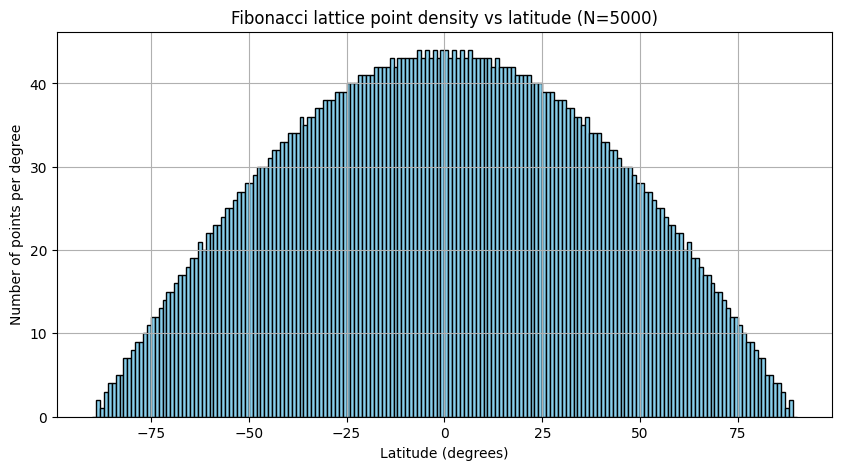

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# --- Parameters ---
R = 6371
N = 5000  # number of Fibonacci points

# --- Fibonacci lattice ---
indices = np.arange(0, N, dtype=float) + 0.5
phi = np.arccos(1 - 2*indices/N)  # polar angle
lat = 90 - np.degrees(phi)         # latitude in degrees

# --- Compute approximate density ---
# Bin latitudes into 180 bins
bins = np.linspace(-90, 90, 181)
hist, edges = np.histogram(lat, bins=bins)
bin_centers = (edges[:-1] + edges[1:]) / 2

# Normalize density by bin width
density = hist / np.diff(edges)

# --- Plot ---
plt.figure(figsize=(10, 5))
plt.bar(bin_centers, density, width=1.0, color='skyblue', edgecolor='k')
plt.xlabel('Latitude (degrees)')
plt.ylabel('Number of points per degree')
plt.title(f'Fibonacci lattice point density vs latitude (N={N})')
plt.grid(True)
plt.show()

c:\Users\Mike\anaconda3\envs\py310_cuda128_torch27\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning:

Creating legend with loc="best" can be slow with large amounts of data.



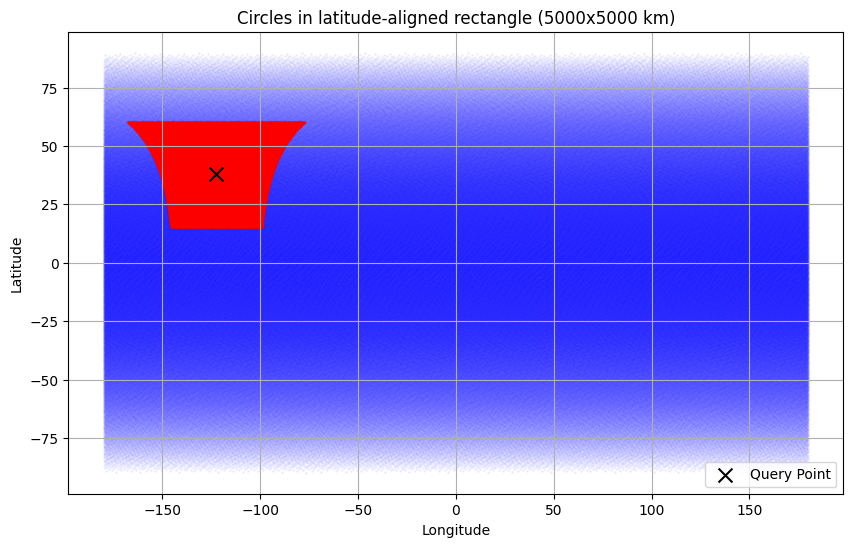

Number of circles in rectangle: 38908


In [7]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Generate circle centers using Fibonacci lattice ---
R = 6371          # Earth radius in km
r_circle = 15     # Circle radius in km

A_earth = 4 * np.pi * R**2
A_circle = np.pi * r_circle**2
N = int(A_earth / A_circle * 1.1)

indices = np.arange(0, N, dtype=float) + 0.5
phi = np.arccos(1 - 2*indices/N)
theta = np.pi * (1 + 5**0.5) * indices

lat = 90 - np.degrees(phi)
lon = np.degrees(theta % (2*np.pi)) - 180

# --- 2. Rectangle parameters ---
query_lat = 37.7749
query_lon = -122.4194
rect_width_km = 5000
rect_height_km = 5000

# --- 3. Compute latitude bounds ---
deg_per_km_lat = 360 / (2 * np.pi * R)
lat_half_delta = rect_height_km / 2 * deg_per_km_lat
lat_min = query_lat - lat_half_delta
lat_max = query_lat + lat_half_delta

# --- 4. Compute east-west km distances at each latitude ---
lat_rads = np.radians(lat)
lon_rads = np.radians(lon)
query_lat_rad = np.radians(query_lat)
query_lon_rad = np.radians(query_lon)

# Horizontal distance along latitude circle
delta_lon = np.radians(lon - query_lon)
east_west_km = R * np.cos(lat_rads) * delta_lon  # east-west distance

# Vertical distance along meridian
north_south_km = R * (lat_rads - query_lat_rad)

# --- 5. Select points inside rectangle ---
within_idx = np.where(
    (np.abs(north_south_km) <= rect_height_km / 2) &
    (np.abs(east_west_km) <= rect_width_km / 2)
)[0]

# --- 6. Plot ---
deg_per_km = 1 / (2 * np.pi * R) * 360
marker_size = (r_circle * deg_per_km * 10)**2

plt.figure(figsize=(10, 6))
plt.scatter(lon, lat, s=1, color='blue', alpha=0.05)
plt.scatter(lon[within_idx], lat[within_idx], s=marker_size, color='red', alpha=0.3)
plt.scatter([query_lon], [query_lat], color='black', marker='x', s=100, label='Query Point')

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title(f'Circles in latitude-aligned rectangle ({rect_width_km}x{rect_height_km} km)')
plt.grid(True)
plt.legend()
plt.show()

print(f"Number of circles in rectangle: {len(within_idx)}")